# Logistic Regression vs LightGBM vs DPCNN

Word + char TF-IDF logistic regression, TF-IDF LightGBM and DPCNN, trained and evaluated on the shared 5 stratified folds with `comment_heavy` as input.

In [1]:
import sys
from pathlib import Path

if "google.colab" in sys.modules:
    !git clone -q https://github.com/mnhhuyen/AI4SE_toxic_comments.git
    %cd AI4SE_toxic_comments
    !pip install -q -e ".[dev]" lightgbm tabulate

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

## Data and folds

In [2]:
import pandas as pd

from toxic_comments.cleaning import process_cleaning, validate_training_data
from toxic_comments.config import (ID_COLUMN, K_FOLD_DATA_DIR, LABEL_COLUMNS, MODELS_DIR,
                                   RAW_DATA_DIR, RESULTS_DIR)
from toxic_comments.splits import save_kfold_datasets

TEXT_COLUMNS = ["comment_text", "comment_light", "comment_heavy"]

if not list(K_FOLD_DATA_DIR.glob("fold_*/test.csv")):
    data = process_cleaning(validate_training_data(pd.read_csv(RAW_DATA_DIR / "train.csv")))
    data[TEXT_COLUMNS] = data[TEXT_COLUMNS].fillna("").astype(str)
    data = data[data["is_empty_heavy"] == 0].reset_index(drop=True)
    save_kfold_datasets(data[[ID_COLUMN, *TEXT_COLUMNS, *LABEL_COLUMNS]], n_splits=5, strategy="stratified")

sorted(path.name for path in K_FOLD_DATA_DIR.glob("fold_*"))

['fold_1', 'fold_2', 'fold_3', 'fold_4', 'fold_5']

## Training

In [3]:
from toxic_comments.train import train_from_folds

MODELS = ["word_char_logistic_regression", "tfidf_lightgbm", "dpcnn"]
MODEL_KWARGS = {
    "word_char_logistic_regression": {"max_features": 20_000},
    "tfidf_lightgbm": {"max_features": 20_000},
}

for name in MODELS:
    if (RESULTS_DIR / f"{name}_fold_metrics.csv").exists():
        print(f"{name}: fold results found, skipping training")
        continue
    train_from_folds(folds_dir=K_FOLD_DATA_DIR, model_name=name, output_dir=MODELS_DIR,
                     **MODEL_KWARGS.get(name, {}))

word_char_logistic_regression: fold results found, skipping training
tfidf_lightgbm: fold results found, skipping training
dpcnn: fold results found, skipping training


## Results (mean ± std over 5 folds)

In [4]:
METRICS = ["subset_accuracy", "hamming_loss", "micro_precision", "micro_recall",
           "micro_f1", "macro_f1", "micro_roc_auc", "macro_roc_auc"]

folds = pd.concat([pd.read_csv(RESULTS_DIR / f"{name}_fold_metrics.csv") for name in MODELS])
stats = folds.groupby("model_name")[METRICS].agg(["mean", "std"]).loc[MODELS]
summary = pd.DataFrame({
    metric: stats[(metric, "mean")].map("{:.4f}".format) + " ± " + stats[(metric, "std")].map("{:.4f}".format)
    for metric in METRICS
}).T
print(summary.to_markdown())

|                 | word_char_logistic_regression   | tfidf_lightgbm   | dpcnn           |
|:----------------|:--------------------------------|:-----------------|:----------------|
| subset_accuracy | 0.8945 ± 0.0018                 | 0.9200 ± 0.0009  | 0.9183 ± 0.0031 |
| hamming_loss    | 0.0238 ± 0.0006                 | 0.0182 ± 0.0004  | 0.0182 ± 0.0005 |
| micro_precision | 0.6322 ± 0.0073                 | 0.8393 ± 0.0065  | 0.8024 ± 0.0364 |
| micro_recall    | 0.8419 ± 0.0066                 | 0.6231 ± 0.0111  | 0.6716 ± 0.0364 |
| micro_f1        | 0.7221 ± 0.0063                 | 0.7151 ± 0.0079  | 0.7298 ± 0.0081 |
| macro_f1        | 0.6070 ± 0.0067                 | 0.5483 ± 0.0160  | 0.5505 ± 0.0177 |
| micro_roc_auc   | 0.9861 ± 0.0003                 | 0.9781 ± 0.0008  | 0.9820 ± 0.0009 |
| macro_roc_auc   | 0.9816 ± 0.0012                 | 0.9709 ± 0.0026  | 0.9743 ± 0.0020 |


## Per-label results

In [5]:
per_label = pd.concat([pd.read_csv(RESULTS_DIR / f"{name}_fold_per_label.csv") for name in MODELS])

for metric in ["f1", "precision", "recall", "roc_auc"]:
    table = per_label.pivot_table(index="label", columns="model_name", values=metric)[MODELS]
    print(f"\n{metric}\n{table.loc[LABEL_COLUMNS].round(4).to_markdown()}")


f1
| label         |   word_char_logistic_regression |   tfidf_lightgbm |   dpcnn |
|:--------------|--------------------------------:|-----------------:|--------:|
| toxic         |                          0.7665 |           0.7479 |  0.7657 |
| severe_toxic  |                          0.4649 |           0.2845 |  0.4176 |
| obscene       |                          0.811  |           0.8017 |  0.8016 |
| threat        |                          0.4418 |           0.369  |  0.2925 |
| insult        |                          0.7077 |           0.6914 |  0.7074 |
| identity_hate |                          0.45   |           0.3954 |  0.3183 |

precision
| label         |   word_char_logistic_regression |   tfidf_lightgbm |   dpcnn |
|:--------------|--------------------------------:|-----------------:|--------:|
| toxic         |                          0.6976 |           0.8906 |  0.8438 |
| severe_toxic  |                          0.3374 |           0.4662 |  0.5366 |
| obscene    

## Comparison chart

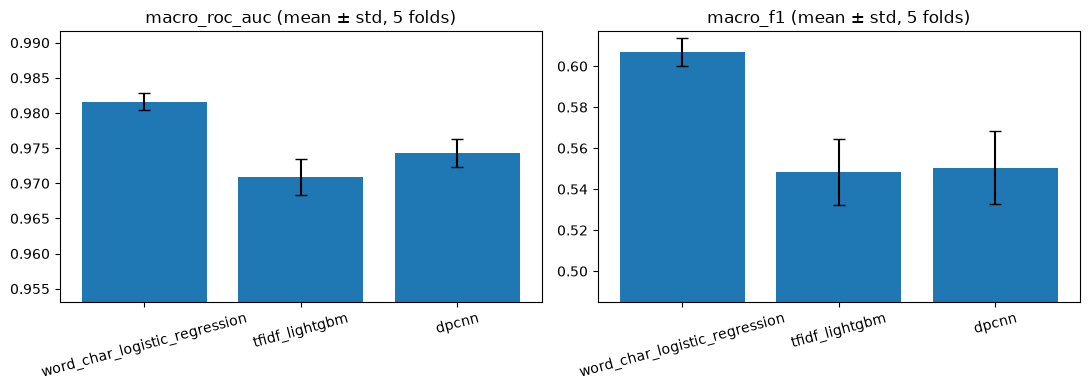

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric in zip(axes, ["macro_roc_auc", "macro_f1"]):
    stats = folds.groupby("model_name")[metric].agg(["mean", "std"]).loc[MODELS]
    ax.bar(stats.index, stats["mean"], yerr=stats["std"], capsize=4)
    ax.set_title(f"{metric} (mean ± std, 5 folds)")
    ax.set_ylim(stats["mean"].min() - 3 * stats["std"].max() - 0.01, min(1, stats["mean"].max() + 0.01))
    ax.tick_params(axis="x", rotation=15)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "logreg_gbm_dpcnn_comparison.png", dpi=150)
plt.show()

## Effect size between models

Difference of fold means divided by the pooled standard deviation; `|σ| ≥ 2` is treated as a real difference.

In [7]:
import itertools

import numpy as np


def effect_size(data, metric, model_a, model_b):
    a = data.loc[data["model_name"] == model_a, metric].to_numpy()
    b = data.loc[data["model_name"] == model_b, metric].to_numpy()
    diff = a.mean() - b.mean()
    pooled_std = np.sqrt(a.std(ddof=1) ** 2 + b.std(ddof=1) ** 2)
    return diff, pooled_std, diff / pooled_std


for metric in ["macro_roc_auc", "macro_f1", "micro_f1"]:
    print(f"\n{metric}")
    for model_a, model_b in itertools.combinations(MODELS, 2):
        diff, pooled_std, n_std = effect_size(folds, metric, model_a, model_b)
        verdict = "real difference" if abs(n_std) >= 2 else "within fold noise"
        print(f"  {model_a} vs {model_b}: Δ={diff:+.4f}, pooled std={pooled_std:.4f} ({n_std:+.1f}σ) -> {verdict}")


macro_roc_auc
  word_char_logistic_regression vs tfidf_lightgbm: Δ=+0.0107, pooled std=0.0028 (+3.8σ) -> real difference
  word_char_logistic_regression vs dpcnn: Δ=+0.0073, pooled std=0.0023 (+3.1σ) -> real difference
  tfidf_lightgbm vs dpcnn: Δ=-0.0034, pooled std=0.0033 (-1.0σ) -> within fold noise

macro_f1
  word_char_logistic_regression vs tfidf_lightgbm: Δ=+0.0587, pooled std=0.0173 (+3.4σ) -> real difference
  word_char_logistic_regression vs dpcnn: Δ=+0.0565, pooled std=0.0189 (+3.0σ) -> real difference
  tfidf_lightgbm vs dpcnn: Δ=-0.0022, pooled std=0.0239 (-0.1σ) -> within fold noise

micro_f1
  word_char_logistic_regression vs tfidf_lightgbm: Δ=+0.0070, pooled std=0.0101 (+0.7σ) -> within fold noise
  word_char_logistic_regression vs dpcnn: Δ=-0.0077, pooled std=0.0103 (-0.7σ) -> within fold noise
  tfidf_lightgbm vs dpcnn: Δ=-0.0147, pooled std=0.0113 (-1.3σ) -> within fold noise


## DPCNN training loss (fold 1)

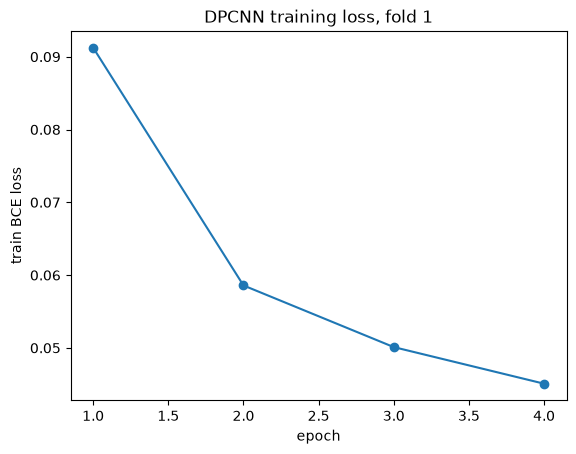

In [8]:
import joblib

fitted = {name: joblib.load(MODELS_DIR / "fold_1" / f"{name}.joblib") for name in MODELS}

loss = fitted["dpcnn"].loss_history_
plt.plot(range(1, len(loss) + 1), loss, marker="o")
plt.xlabel("epoch")
plt.ylabel("train BCE loss")
plt.title("DPCNN training loss, fold 1")
plt.savefig(RESULTS_DIR / "dpcnn_loss_curve.png", dpi=150)
plt.show()

## Example predictions

In [9]:
from toxic_comments.cleaning import clean_heavy, clean_light
from toxic_comments.evaluation import predict_scores

examples = [
    "You are such an idiot, I hope something bad happens to you.",
    "I will find you and kill you",
    "Thanks so much for fixing this, really appreciate it!",
]
cleaned = pd.Series([clean_heavy(clean_light(text)) for text in examples])
scores = {name: predict_scores(model, cleaned) for name, model in fitted.items()}
predictions = pd.DataFrame(
    [scores[name][row] for row in range(len(examples)) for name in MODELS],
    index=pd.MultiIndex.from_product([examples, MODELS], names=["comment", "model"]),
    columns=LABEL_COLUMNS,
)
predictions.round(3)

toxic  \
comment                                            model                                  
You are such an idiot, I hope something bad hap... word_char_logistic_regression  1.000   
                                                   tfidf_lightgbm                 0.943   
                                                   dpcnn                          0.989   
I will find you and kill you                       word_char_logistic_regression  0.999   
                                                   tfidf_lightgbm                 0.803   
                                                   dpcnn                          0.867   
Thanks so much for fixing this, really apprecia... word_char_logistic_regression  0.001   
                                                   tfidf_lightgbm                 0.008   
                                                   dpcnn                          0.003   

                                                                                  severe_toxic  \
comment                                            model                                         
You are such an idiot, I hope something bad hap... word_char_logistic_regression         0.110   
                                                   tfidf_lightgbm                        0.004   
                                                   dpcnn                                 0.049   
I will find you and kill you                       word_char_logistic_regression         0.191   
                                                   tfidf_lightgbm                        0.044   
                                                   dpcnn                                 0.205   
Thanks so much for fixing this, really apprecia... word_char_logistic_regression         0.000   
                                                   tfidf_lightgbm                        0.000   
                                                   dpcnn                                 0.000   

                                                                                  obscene  \
comment                                            model                                    
You are such an idiot, I hope something bad hap... word_char_logistic_regression    0.856   
                                                   tfidf_lightgbm                   0.366   
                                                   dpcnn                            0.622   
I will find you and kill you                       word_char_logistic_regression    0.085   
                                                   tfidf_lightgbm                   0.052   
                                                   dpcnn                            0.330   
Thanks so much for fixing this, really apprecia... word_char_logistic_regression    0.001   
                                                   tfidf_lightgbm                   0.004   
                                                   dpcnn                            0.000   

                                                                                  threat  \
comment                                            model                                   
You are such an idiot, I hope something bad hap... word_char_logistic_regression   0.678   
                                                   tfidf_lightgbm                  0.000   
                                                   dpcnn                           0.019   
I will find you and kill you                       word_char_logistic_regression   1.000   
                                                   tfidf_lightgbm                  0.987   
                                                   dpcnn                           0.785   
Thanks so much for fixing this, really apprecia... word_char_logistic_regression   0.000   
                                                   tfidf_lightgbm                  0.000   
                                                   dpcnn 

## Error analysis (fold 1 test set)

In [10]:
best_model_name = folds.groupby("model_name")["macro_roc_auc"].mean().idxmax()
print(f"Best model by macro ROC-AUC: {best_model_name}")

test = pd.read_csv(K_FOLD_DATA_DIR / "fold_1" / "test.csv")
test["comment_heavy"] = test["comment_heavy"].fillna("").astype(str)
test["toxic_prob"] = predict_scores(fitted[best_model_name], test["comment_heavy"])[:, 0]
pd.set_option("display.max_colwidth", 120)

print("False negatives (toxic, lowest score):")
display(test[test["toxic"] == 1].nsmallest(5, "toxic_prob")[["comment_text", "toxic_prob"]])
print("False positives (clean, highest score):")
display(test[test["toxic"] == 0].nlargest(5, "toxic_prob")[["comment_text", "toxic_prob"]])

Best model by macro ROC-AUC: word_char_logistic_regression


False negatives (toxic, lowest score):


,comment_text,toxic_prob
12070,"""\n\n HE BELIEVES IN OPENNESS BUT CLOSES HIS PAGE - BULL$HIT WE ALL SEE THRU U JIMBO \n\nWikipedia Founder Hit With ...",0.001819
15265,Admins have free reign? \n\nPeople keep removing the above questions from a user and I believe they are ligitimate q...,0.003790
22716,"Doug Weller is a compulsive liar and a slanderer. He is aware that Filiquarian Publishing, LLC. without question fol...",0.004803
8602,Thanks\nThanks for participating in the conspiracy against me.,0.004965
9006,"""\n\n """"SCIENTIFIC"""" SKEPTIC ???! \n\nHe never went to college, so why this article calls him a scientific skeptic ?...",0.005433


False positives (clean, highest score):


,comment_text,toxic_prob
19926,Some reading material \n\nI was listening to The Ballad of JamesBWatson and was inspired to make some poetry\n\nYou ...,1.000000
2531,"""Kurt and Dave get it on?==\n\nGroaning Kurt released his cock. For the past week he hadn't been able to get off. He...",1.000000
26130,"""\nSeriously. The blame the victim bullshit here has to stop. Or have you not noticed that saying anything about Mal...",0.999993
15236,"""\n\n Hey What's Up \n\nHey Pink Floyd guy,\nI started editing on Wikipedia just to keep my mind occupied, I'm going...",0.999986
10495,"""\n\n Get a life \n\nListen you moron, You are the one who needs to be blocked for """"Disruptive editing"""". Who the ...",0.999937


## Findings

- **Word + char logistic regression is the strongest model.** It leads on macro ROC-AUC (0.9816) and macro-F1 (0.607), beats both other models on every fold, and has the lowest fold variance. Character n-grams match misspelled and obfuscated words that word-level features miss.
- **The models sit at different precision/recall trade-offs.** Logistic regression uses balanced class weights and predicts many positives (micro recall 0.84, precision 0.63); LightGBM and DPCNN are unweighted and conservative (precision 0.80–0.84, recall 0.62–0.67). F1 at threshold 0.5 therefore reflects the decision rule as much as the model; ROC-AUC is the fairer comparison.
- **Rare labels decide macro-F1.** On `toxic`, `obscene` and `insult` the three models are close; the gap comes from `severe_toxic`, `threat` and `identity_hate`, where the unweighted models recover only 20–35% of positives.
- **DPCNN is under-trained, not weak.** Its loss is still falling at epoch 4 and it learns embeddings from scratch, yet it has the highest micro-F1 (0.730, within fold noise of the other two) and ranks `severe_toxic` best (ROC-AUC 0.988). Pretrained embeddings, more epochs and `use_pos_weight=True` are the obvious next steps.
- **LightGBM on sparse TF-IDF is the weakest option.** Trees split on a few n-grams at a time, while a linear model pools weak evidence from all of them. DPCNN vs LightGBM is within fold noise on macro ROC-AUC and macro-F1.
- **Subset accuracy is misleading here**: about 90% of comments are clean, so predicting fewer positives inflates it.